# Spatial domains of an FFPE breast tumour (10x Visium CytAssist)

**Goal**: identify spatial domains on the H&E-stained section, describe what each one contains, find genes with a spatial structure, and compare the tumour domains with those published for this sample. The clustered object is then deconvolved with the single-cell reference (notebook 03).

**What changes compared with single-cell data.** A Visium spot is 55 µm wide (centre-to-centre spacing 100 µm) and captures the RNA of **several cells**, often 5 to 20. Each row of the matrix is therefore a mixture of cells, but its position on the section is known. Visium CytAssist uses the same probe panel as Chromium Flex, so all single-cell genes are also measured here.

The pipeline script `bin/qc_spatial.py` implements the same steps.

In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

# Repository root = the first parent folder that contains envs/python.yml
ROOT = Path.cwd()
while not (ROOT / "envs" / "python.yml").exists():
    if ROOT == ROOT.parent:   # reached "/" without finding it
        raise FileNotFoundError("Run this notebook from inside the repository")
    ROOT = ROOT.parent
DATA = ROOT / "data"
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, frameon=False)
SEED = 0

## 1. Loading the data

Space Ranger outputs the count matrix and a `spatial/` folder: the H&E image (`tissue_hires_image.png`), the position of each spot (`tissue_positions.csv`) and the scale factors between spot coordinates and image pixels (`scalefactors_json.json`). `sq.read.visium` gathers everything into one AnnData object:
- `adata.obs["in_tissue"]`, `["array_row"]`, `["array_col"]`: whether the spot is under the tissue, and its row and column in the hexagonal grid of spots;
- `adata.obsm["spatial"]`: the (x, y) position of each spot, in pixels of the full-resolution image;
- `adata.uns["spatial"]`: the downscaled images and the scale factors.

In [25]:
# Read the Space Ranger folder: the matrix file is given separately, the folder must also contain spatial/
adata = sq.read.visium(DATA / "visium", counts_file="filtered_feature_bc_matrix.h5")
adata.var_names_make_unique()   # a few gene symbols are duplicated
print(adata)
print("coordinates of the first 3 spots (pixels):\n", adata.obsm["spatial"][:3])

/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 4992 × 18085
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
coordinates of the first 3 spots (pixels):
 [[ 4131  4636]
 [13355 16640]
 [ 8845 12067]]


/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [26]:
# uns["spatial"] is a dictionary keyed by sample name (one object can hold several sections)
library_id = list(adata.uns["spatial"].keys())[0]
print("sample:", library_id)
print("content:", list(adata.uns["spatial"][library_id].keys()))
print("scale factors:", adata.uns["spatial"][library_id]["scalefactors"])
# Image dimensions: (height, width, 3 colour channels)
print("hires image:", adata.uns["spatial"][library_id]["images"]["hires"].shape)

sample: CytAssist_FFPE_Human_Breast_Cancer
content: ['metadata', 'images', 'scalefactors']
scale factors: {'regist_target_img_scalef': 0.2781512, 'tissue_hires_scalef': 0.092717074, 'tissue_lowres_scalef': 0.027815122, 'fiducial_diameter_fullres': 191.75371240966362, 'spot_diameter_fullres': 127.8358082731091}
hires image: (2000, 1809, 3)


**Observations.** 4,992 spots × 18,085 genes. A Visium capture area holds exactly 4,992 spots, so **every spot of the capture area is under tissue**. The hires image (2,000 × 1,809 pixels) is the full-resolution image scaled by `tissue_hires_scalef` = 0.093, so the original image is about 21,600 pixels high. A spot (55 µm) is 127.8 pixels wide on the full-resolution image (`spot_diameter_fullres`, computed by Space Ranger from the fiducial markers), i.e. **~0.43 µm per pixel**.

The H&E image alone, without spots:

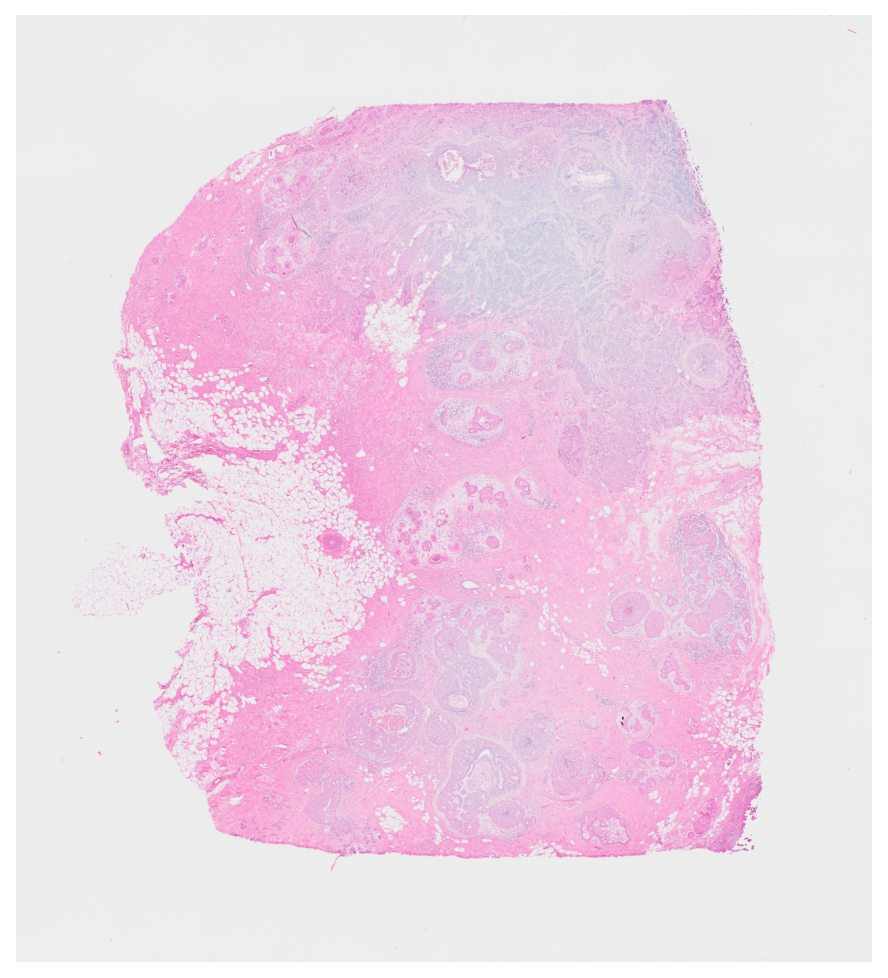

In [27]:
# color=None: only the H&E image is drawn
sq.pl.spatial_scatter(adata, color=None, figsize=(6, 6))

**Observations on the H&E section** (to be checked against expression data): adipose tissue on the left (empty, lace-like fat cells), pink collagen-rich stroma, round and well-delimited ducts filled with tumour cells (the typical aspect of ductal carcinoma in situ, DCIS), a large dense purple region without clear boundaries at the top right (possibly invasive tumour), and small vessels.

## 2. Spot quality control

As for single cells, each spot gets a total number of molecules (`total_counts`) and of detected genes (`n_genes_by_counts`). The spatial information adds a criterion: poor spots scattered in fat or loose stroma are a real, cell-poor tissue region, whereas poor spots along an edge or a tear are a technical artefact. There is no doublet detection and no mitochondrial filter: a spot is a mixture by design, and its MT fraction reflects its composition more than its quality.

        total_counts  n_genes_by_counts
count    4992.000000        4992.000000
mean    23096.515625        5956.958734
std     22846.322266        3180.350161
min        39.000000          38.000000
1%       1253.370000         983.460000
5%       2016.850000        1478.100000
50%     13532.000000        5712.000000
max    161801.000000       13394.000000


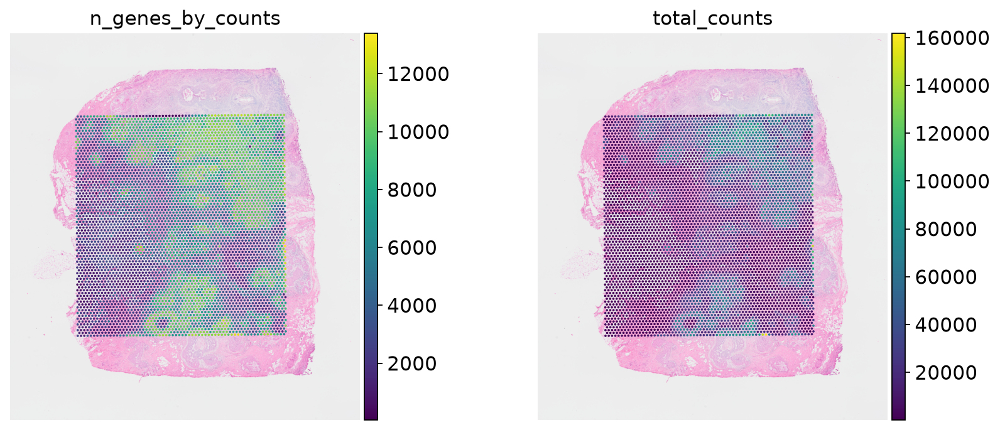

In [28]:
# Adds total_counts and n_genes_by_counts to adata.obs (and per-gene metrics to adata.var)
sc.pp.calculate_qc_metrics(adata, percent_top=None, log1p=False, inplace=True)
sq.pl.spatial_scatter(adata, color=["n_genes_by_counts", "total_counts"], ncols=2, figsize=(5, 5))
print(adata.obs[["total_counts", "n_genes_by_counts"]].describe(percentiles=[0.01, 0.05, 0.5]))

**Observations.** The spots cover only the 6.5 mm capture area in the middle of the section; the tissue extends beyond it. Spots are rich in the round ducts and in the dense region at the top right (8,000-13,000 genes), and poor towards the fat on the left and in the stroma between ducts. A spot captures ~6 times more molecules than a single cell (median 13,532 molecules and 5,712 genes, against 2,191 and 1,480 per cell in notebook 01). The `total_counts` map is compressed by a few very rich spots (up to 161,801 molecules).

Where would the removed spots be for several thresholds?

min_counts =  250 ->   10 spots removed
min_counts =  500 ->   11 spots removed
min_counts = 1000 ->   29 spots removed
min_counts = 2000 ->  245 spots removed


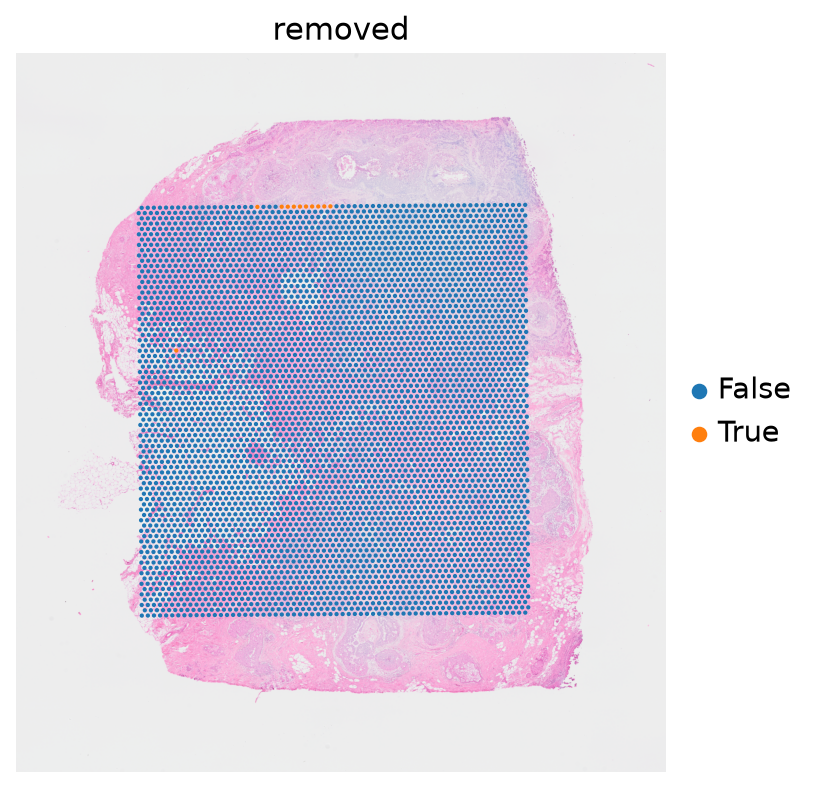

In [29]:
# Number of spots below each candidate threshold
for cutoff in [250, 500, 1000, 2000]:
    print(f"min_counts = {cutoff:>4} -> {(adata.obs['total_counts'] < cutoff).sum():>4} spots removed")

MIN_COUNTS = 500
# Map of the spots that would be removed (True/False converted to categories: two colours instead of a gradient)
adata.obs["removed"] = (adata.obs["total_counts"] < MIN_COUNTS).astype(str).astype("category")
sq.pl.spatial_scatter(adata, color="removed", figsize=(5, 5))

In [30]:
# Remove poor spots and genes detected in fewer than 10 spots
# (Scanpy calls rows "cells": here min_cells means "at least 10 spots")
sc.pp.filter_cells(adata, min_counts=MIN_COUNTS)
sc.pp.filter_genes(adata, min_cells=10)
# Keep a COPY of the raw counts before normalisation: RCTD needs raw integer counts
adata.layers["counts"] = adata.X.copy()
# Remove the helper column and the colours stored for its plot
del adata.obs["removed"]
adata.uns.pop("removed_colors", None)
adata

AnnData object with n_obs × n_vars = 4981 × 18031
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'total_counts', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'spatial'
    obsm: 'spatial'
    layers: 'counts'

**Chosen threshold: 500 molecules.** It removes 11 spots: 10 of them form the **first row at the top edge** of the capture area, a technical edge artefact (the tissue above looks like its neighbours on the H&E image), plus one isolated spot. 1,000 would also remove poor but real spots in the fat at the left edge, and 2,000 (245 spots) would cut into fat and stroma. Result: **4,981 spots × 18,031 genes**. In the pipeline, this value is the parameter `spot_min_counts = 500` of `nextflow.config`.

## 3. Clustering into spatial domains

Same steps as for single cells: normalisation to 10,000 molecules per spot, log1p, 2,000 highly variable genes, PCA, neighbour graph, UMAP and Leiden at three resolutions. The interpretation differs: a cluster of spots is not a cell type but a **domain**, a recurring mixture of cells. The clustering does not know the spot positions: if clusters still form continuous regions that follow the H&E structures, they reflect the tissue organisation rather than noise.

resolution 0.4: 9 clusters
resolution 0.8: 17 clusters
resolution 1.2: 21 clusters


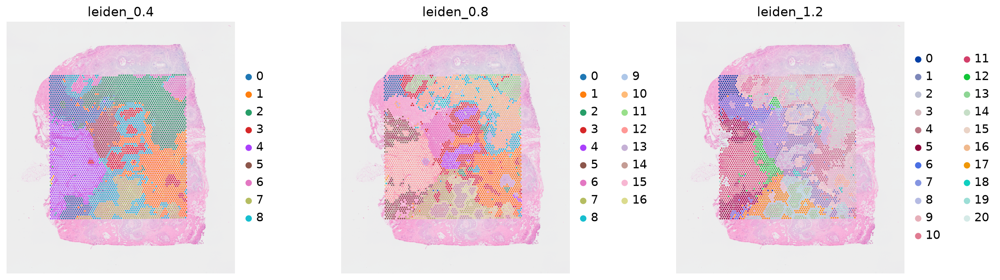

In [31]:
sc.pp.normalize_total(adata, target_sum=1e4)   # same total for every spot
sc.pp.log1p(adata)                              # log(1 + x)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
sc.tl.pca(adata, mask_var="highly_variable", random_state=SEED)
# Graph of spots with similar expression profiles (wherever they are on the section)
sc.pp.neighbors(adata, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)

# Leiden at three resolutions, each stored in its own column
for res in [0.4, 0.8, 1.2]:
    sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}",
                 flavor="igraph", n_iterations=2, directed=False, random_state=SEED)
    print(f"resolution {res}: {adata.obs[f'leiden_{res}'].nunique()} clusters")

# Clusters drawn on the section
sq.pl.spatial_scatter(adata, color=[f"leiden_{res}" for res in [0.4, 0.8, 1.2]], ncols=3, figsize=(5, 5))

**Observations.** 9, 17 and 21 clusters at resolutions 0.4, 0.8 and 1.2. At every resolution the clusters form **continuous regions** that follow the H&E structures, although positions were not used: the tissue is organised into domains that expression alone recovers. At 0.8 the two kinds of round ducts (bottom and centre) take different clusters; at 1.2 small fragments appear inside homogeneous regions.

### Choosing the resolution

Without prior knowledge, several criteria help: each cluster should have its own genes, clusters should be stable, and in spatial data they should be continuous. **Stability** is measured below by re-running Leiden with three random seeds and comparing the results with the adjusted Rand index (ARI: 1 = identical, 0 = no better than chance).

In [32]:
from sklearn.metrics import adjusted_rand_score

for res in [0.4, 0.8, 1.2]:
    runs = []
    for seed in [0, 1, 2]:
        # Same clustering with a different random seed, stored in a temporary column
        sc.tl.leiden(adata, resolution=res, key_added="tmp", flavor="igraph",
                     n_iterations=2, directed=False, random_state=seed)
        runs.append(adata.obs["tmp"].copy())
    # Agreement of seeds 1 and 2 with seed 0
    ari = [adjusted_rand_score(runs[0], r) for r in runs[1:]]
    print(f"resolution {res}: agreement between seeds = {ari[0]:.2f} and {ari[1]:.2f}")
del adata.obs["tmp"]

resolution 0.4: agreement between seeds = 0.85 and 0.74
resolution 0.8: agreement between seeds = 0.73 and 0.79
resolution 1.2: agreement between seeds = 0.73 and 0.86


**Observations.** All three resolutions are equally stable (ARI 0.73-0.86): differences between seeds within a resolution are as large as between resolutions. Moderate stability is expected in spatial data, because spots at the boundary between two domains are mixtures and switch side from one run to another. This criterion does not discriminate here.

### Checking a scattered cluster

At resolution 0.8, cluster 3 looks scattered on the section, which could be noise. Its location, QC metrics and specific genes are checked below.

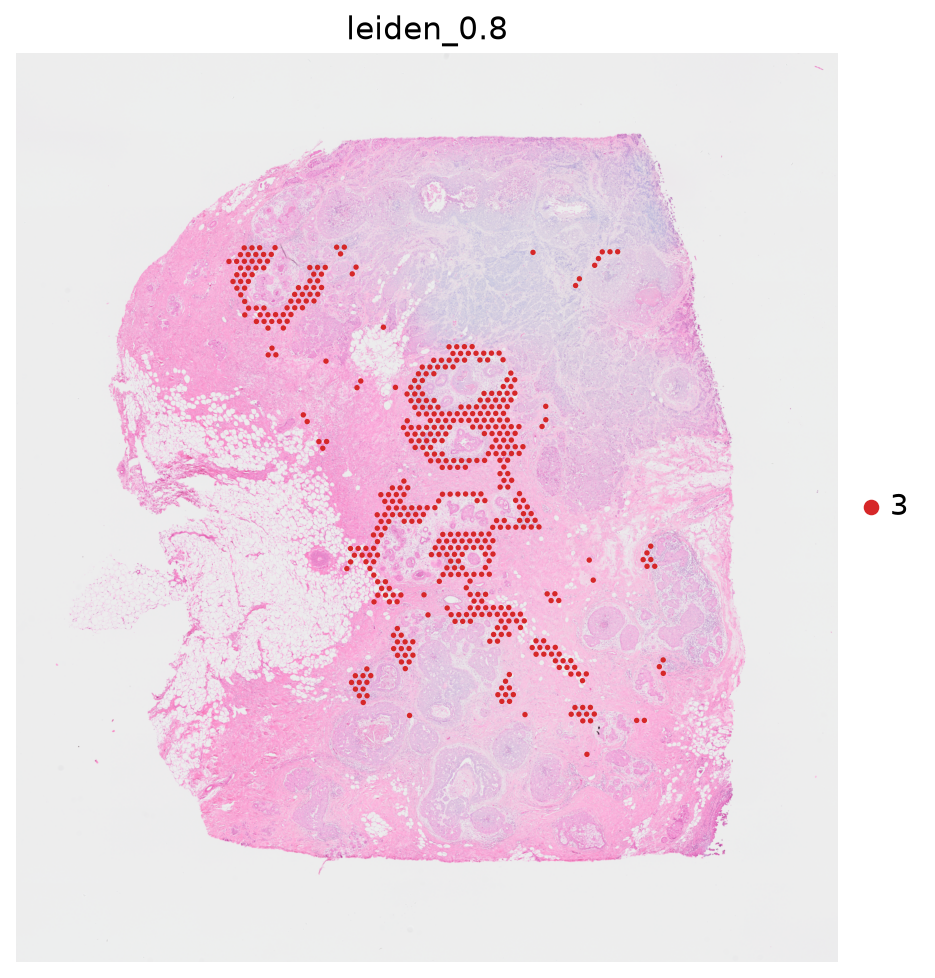

In [33]:
# Only the spots of cluster 3 are coloured
sq.pl.spatial_scatter(adata, color="leiden_0.8", groups=["3"], figsize=(6, 6))

In [34]:
# Median QC metrics per cluster: a noise cluster would often be made of poor spots
adata.obs.groupby("leiden_0.8", observed=True)[["total_counts", "n_genes_by_counts"]].median()

,total_counts,n_genes_by_counts
leiden_0.8,,
0,7437.0,4293.0
1,6306.0,3505.0
2,14468.0,6056.0
3,18922.0,6799.0
4,30367.0,8614.5
5,3827.5,2461.5
6,11342.0,4853.0
7,10226.5,5137.0
8,24163.5,7772.0


In [35]:
# Genes that distinguish cluster 3 from all other spots
sc.tl.rank_genes_groups(adata, groupby="leiden_0.8", groups=["3"], method="wilcoxon")
sc.get.rank_genes_groups_df(adata, group="3").head(10)

,names,scores,logfoldchanges,pvals,pvals_adj
0,CD74,30.604321,1.820606,1.072190e-205,1.933265e-201
1,CXCR4,28.353865,2.123060,7.500270e-177,6.761868e-173
2,LYZ,26.886410,2.047127,3.166798e-159,1.903351e-155
3,IL7R,26.767748,2.683868,7.674615e-158,3.459524e-154
4,TRAC,26.404465,2.353641,1.217579e-153,4.390832e-150
5,B2M,25.979738,1.018434,8.391481e-149,2.521780e-145
6,TRBC2,25.767714,2.324062,2.041073e-146,5.257512e-143
7,IGKC,25.380621,2.692316,4.127951e-142,9.303886e-139
8,CIITA,25.296953,2.160974,3.450585e-141,6.913056e-138
9,CD52,24.715765,2.163622,7.240028e-135,1.305450e-131


**Observations.** Cluster 3 has a coherent **immune** signature: T cells (IL7R, TRAC, TRBC2, CD52, CXCR4), antigen-presenting cells (CD74, CIITA, LYZ) and plasma cells (IGKC), with normal counts (median 18,922 molecules). On the section it outlines the tumour ducts and forms lymphoid aggregates: an immune infiltrate, scattered because the biology is. Resolution 0.8 is right to separate it.

**Chosen resolution: 0.8**, which separates the two kinds of duct-like structures and the immune infiltrate without the fragments seen at 1.2. In the pipeline, the parameter `leiden_resolution` is shared by the single-cell and spatial steps; 0.8 is used for both.

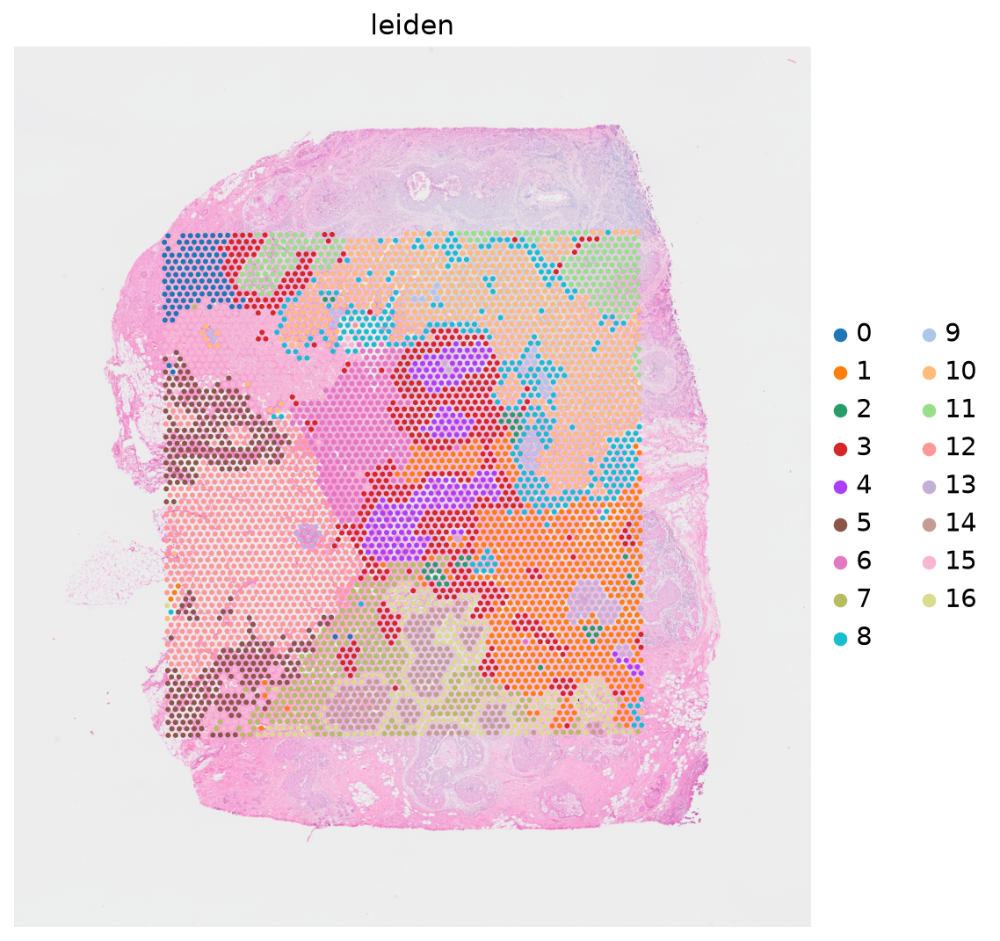

In [36]:
RESOLUTION = 0.8
# Copy the chosen clustering into a column simply named "leiden", used by all following cells
adata.obs["leiden"] = adata.obs[f"leiden_{RESOLUTION}"]
sq.pl.spatial_scatter(adata, color="leiden", figsize=(7, 7))
plt.savefig(FIG / "02_spatial_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. What does each domain contain?

The genes that distinguish each domain (`rank_genes_groups`) and the curated cell-type markers of notebook 01 (`assets/markers_breast.csv`) describe which mixture of cells each domain contains. Unlike single cells, several cell types are expected in each row of the dotplot: what matters is the dominant type and what distinguishes a domain from the others.

In [37]:
# Top 8 genes of each domain against all other spots (one column per domain)
pd.set_option("display.max_columns", None)
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(8)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,APOD,CTHRC1,TAGLN,CD74,MMP11,TNXB,COL6A3,IGHA1,DCAF7,SCD,DCAF7,SLC39A6,FABP4,CPB1,SLC12A2,TNXB,IKZF3
1,PLXDC1,SPARC,ACTA2,CXCR4,KRT17,DCN,EMILIN1,APOD,HMGCS2,FADS2,MIEN1,TFF1,GPX3,MUCL1,SPOP,MGP,SPOP
2,PI16,MMP2,IGFBP7,LYZ,INHBA,GSN,SFRP4,JCHAIN,CDH2,HMGCS2,HSP90AA1,MSMB,CFD,FAM3B,IKZF3,OGN,ITGB6
3,TXNIP,COL1A1,JAG1,IL7R,KRT14,FSTL1,C1R,SCGB2A2,MIEN1,PSCA,TACO1,TFF3,PLIN1,IFI27,ZNF652,COL14A1,AGR2
4,CXCL12,POSTN,MYH11,TRAC,SULF1,CPE,CHI3L1,MGP,TACO1,ECM1,MT-ND1,PLAT,ADH1B,LASP1,TTC3,DCN,CEACAM6
5,DCN,BGN,MYL9,B2M,KRT6B,EFEMP1,C3,IGLC1,NRAS,PIP,NRAS,S100P,PLIN4,STARD10,ITGB6,SFRP4,SLC12A2
6,ITM2A,AEBP1,SYNPO,TRBC2,COL10A1,CXCL12,SERPINF1,PI16,ECM1,PGAP3,CDH2,PPDPF,ADIPOQ,TSPAN1,EZR,CXCL12,KRT14
7,SPARCL1,COL1A2,CSRP1,IGKC,TPM1,COL14A1,FBLN1,SFRP1,PVALB,MT-CO2,VMP1,NAT1,G0S2,ARSG,NQO1,FBLN1,TTC3


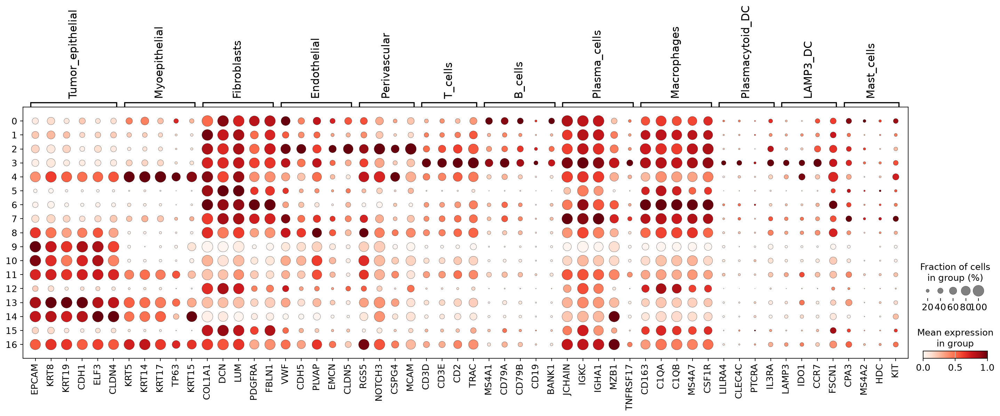

In [38]:
# Curated cell-type markers (genes present in the panel), one row per domain.
# Dot size = fraction of spots expressing the gene; colour = mean expression scaled from 0 to 1 per gene
markers_df = pd.read_csv(ROOT / "assets" / "markers_breast.csv")
markers = {r.cell_type: [g for g in r.genes.split(";") if g in adata.var_names] for r in markers_df.itertuples()}
sc.pl.dotplot(adata, markers, groupby="leiden", standard_scale="var")

**Observations.**
- **Tumour** (epithelial markers): 9 and 10 (DCAF7, MIEN1, PGAP3 from the ERBB2/HER2 amplicon; the richest spots), 11 and 13 (luminal, oestrogen-responsive genes: TFF1, TFF3, SLC39A6, CPB1), 14 and 16 (SLC12A2, ITGB6, and IKZF3, a neighbour of ERBB2 on chromosome 17, probably co-amplified; 16 also expresses myoepithelial keratins).
- **Duct-stroma interface**: 4 (myoepithelial keratins KRT14, KRT17, KRT6B with MMP11, INHBA, COL10A1 from tumour-activated fibroblasts); **tumour-stroma mixture**: 8 (amplicon genes with vessel markers).
- **Stroma**: 1 (activated stroma: CTHRC1, POSTN, MMP2), 6 (fibroblasts with complement genes and macrophages), 0 (APOD, PI16, CXCL12, with B cells), 5 and 15 (loose stroma: TNXB, DCN, OGN; few molecules), 2 (vessels: TAGLN, ACTA2, MYH11).
- **Immune cells and fat**: 3 (immune infiltrate), 7 (plasma cells: IGHA1, JCHAIN), 12 (adipose tissue: FABP4, PLIN1, ADIPOQ, CFD).

The tumour domains on the section:

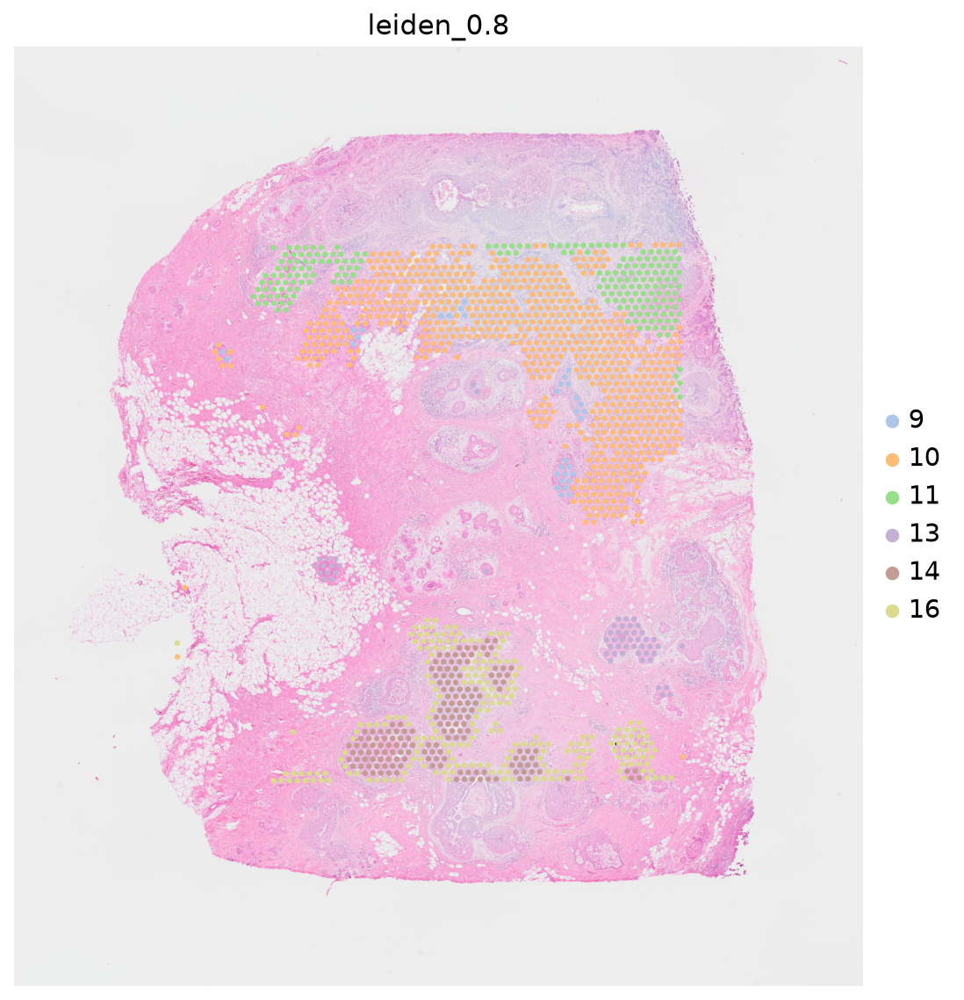

In [39]:
# Only the tumour domains are coloured
sq.pl.spatial_scatter(adata, color="leiden_0.8", groups=["9", "10", "11", "13", "14", "16"], figsize=(7, 7))

**Observations.** 14 and 16 are a group of round ducts at the bottom, with 16 forming a **ring around 14** (tumour centre and periphery). 13 is a single duct on the right, 11 a band at the top, and 9-10 the large dense region at the top right.

The top 50 genes of a domain can be pasted into an enrichment tool such as g:Profiler, which tests which known biological functions are over-represented. For domain 12, the genes are almost all involved in lipid storage and transport (FABP4, PLIN1, PLIN4, ADIPOQ, LPL, CD36, PNPLA2), confirming adipose tissue.

In [40]:
# Top 50 genes of domain 12, as a space-separated list to paste into g:Profiler
genes = sc.get.rank_genes_groups_df(adata, group="12").head(50)["names"].tolist()
print(" ".join(genes))

FABP4 GPX3 CFD PLIN1 ADH1B PLIN4 ADIPOQ G0S2 GSN LPL RNASE1 PNPLA2 CD36 GLUL PDK4 PLTP FTL ALDH2 F13A1 PPP1R1A DEPP1 FSTL1 VIM TNXB APOD CXCL12 ADIRF LYVE1 GPD1 CRYAB EFEMP1 SLC19A3 DCN LIPE SELENOP C1QA LGMN ANXA1 DUSP1 CAVIN1 C1QC CAV1 PLAAT3 EPAS1 GPC3 NNMT HSPB6 FMO2 SERPING1 SRPX


## 5. Spatially variable genes (Moran's I)

A gene can vary a lot without any spatial organisation, or form clear patches. **Moran's I** measures whether neighbouring spots have similar values: close to 1 = patches, close to 0 = random distribution. Its significance is tested by permutation: the values of a gene are shuffled between spots 100 times, which destroys any spatial structure, and the real I is compared with the shuffled ones.

`sq.gr.spatial_neighbors` first builds the graph of **physical** neighbours (6 per spot on the hexagonal grid). It is unrelated to `sc.pp.neighbors` (section 3), which links spots with similar expression wherever they are.

In [41]:
# Graph of physical neighbours on the hexagonal grid
sq.gr.spatial_neighbors(adata)
# Moran's I for the 2,000 highly variable genes (a gene that does not vary cannot form a pattern)
hvg = adata.var_names[adata.var["highly_variable"]]
sq.gr.spatial_autocorr(adata, mode="moran", genes=hvg, n_perms=100, n_jobs=4, seed=SEED, show_progress_bar=False)

# Genes sorted from the most to the least spatially organised
moran = adata.uns["moranI"].sort_values("I", ascending=False)
moran.head(15)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_25393/3910903184.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata)
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/sit

,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
FABP4,0.842879,0.0,0.000069,0.0,0.009901,0.000167,0.0,0.0,0.015854
COL1A2,0.803756,0.0,0.000069,0.0,0.009901,0.000154,0.0,0.0,0.015854
GPX3,0.787571,0.0,0.000069,0.0,0.009901,0.000164,0.0,0.0,0.015854
CDH2,0.785589,0.0,0.000069,0.0,0.009901,0.000138,0.0,0.0,0.015854
APOD,0.778456,0.0,0.000069,0.0,0.009901,0.000145,0.0,0.0,0.015854
HMGCS2,0.778259,0.0,0.000069,0.0,0.009901,0.000175,0.0,0.0,0.015854
CPB1,0.777315,0.0,0.000069,0.0,0.009901,0.000162,0.0,0.0,0.015854
DCAF7,0.772565,0.0,0.000069,0.0,0.009901,0.000139,0.0,0.0,0.015854
TAT,0.771818,0.0,0.000069,0.0,0.009901,0.000154,0.0,0.0,0.015854
SCGB2A2,0.755606,0.0,0.000069,0.0,0.009901,0.000149,0.0,0.0,0.015854


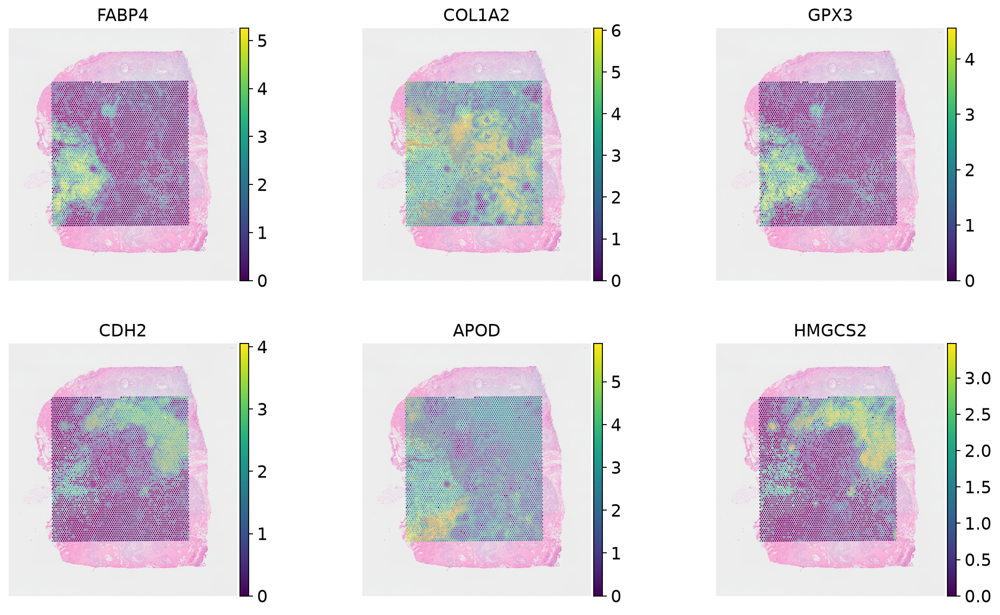

In [42]:
# Maps of the 6 most spatially organised genes
top6 = list(moran.index[:6])
sq.pl.spatial_scatter(adata, color=top6, ncols=3, figsize=(4, 4))
plt.savefig(FIG / "02_top_moran_genes.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations.** The most organised genes (I = 0.74-0.84) draw the main tissue compartments: adipose tissue (FABP4, GPX3, PLIN1), stroma (COL1A2, APOD), the dense tumour region at the top right (CDH2, HMGCS2, DCAF7), ducts (CPB1, PIP, SCGB2A2) and plasma cells (IGHA1). CDH2 encodes N-cadherin, often associated with motile, invasive tumour cells: its pattern supports the invasive nature of the top-right region.

All permutation p-values equal 1/101 = 0.0099, the smallest value reachable with 100 permutations (none of the shuffled versions reaches the real I); `*_fdr_bh` columns are corrected for the 2,000 genes tested (Benjamini-Hochberg). The genes are ranked by I, which measures the strength of the pattern.

## 6. Comparison with the published domains

Janesick et al. describe three distinct tumour domains in this section: **two ductal carcinomas in situ (DCIS #1 and DCIS #2)** and an **invasive** region. 10x published its own clustering of the Visium data (sheet `Visium`); the table below counts the spots of each pair (my domain, published domain).

published_domain,DCIS #1,DCIS #2,adipocytes,immune,invasive,mixed,mixed/invasive,myoepithelial/stromal/immune,stromal,stromal/endothelial,stromal/endothelial/immune
leiden,,,,,,,,,,,
0,0,0,0,1,0,0,0,84,0,12,10
1,0,11,1,15,0,3,0,0,49,281,223
2,0,0,0,0,0,0,0,0,0,0,36
3,0,0,6,197,0,5,0,0,163,12,130
4,0,3,0,12,0,174,0,0,5,0,4
5,0,0,17,0,0,54,0,0,2,288,1
6,0,0,1,0,0,0,0,0,237,1,0
7,0,0,0,1,0,0,0,24,4,115,130
8,0,0,17,22,6,4,188,0,10,67,18


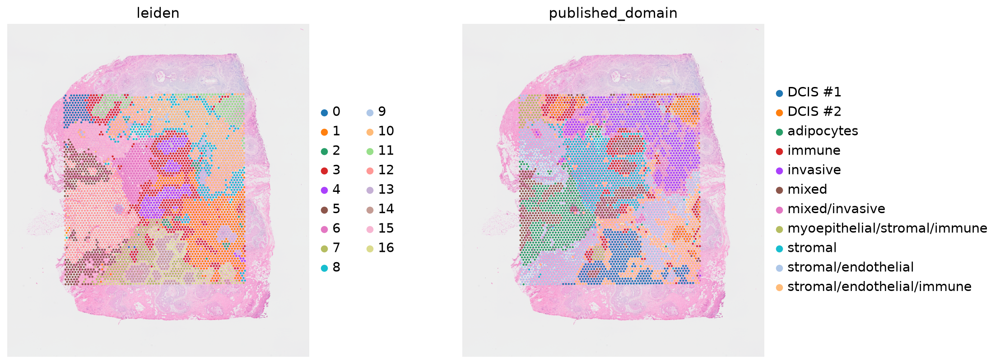

In [43]:
# Published domains, put in the order of our spots
published = pd.read_excel(DATA / "annotations" / "Cell_Barcode_Type_Matrices.xlsx", sheet_name="Visium")
published = published.set_index("Barcode")["Annotation"]
adata.obs["published_domain"] = published.reindex(adata.obs_names).astype("category")

sq.pl.spatial_scatter(adata, color=["leiden", "published_domain"], ncols=2, figsize=(6, 6))
# Number of spots for each (my domain, published domain) pair
pd.crosstab(adata.obs["leiden"], adata.obs["published_domain"])

**Observations.** The three tumour domains are recovered almost exactly: **DCIS #1** = domains 16 (189 spots) and 14 (155), **DCIS #2** = 11 (155) and 13 (41), **invasive** = 10 (560) and 9 (33). DCIS #2 occupies two distant places on the section (the top-right corner and a duct on the right): two separate regions with the same expression programme. Adipocytes (12), the immune domain (3), the tumour-stroma mixture (8, "mixed/invasive") and the duct-stroma interface (4, "mixed") also match. The stroma is split differently by the two analyses: it is a continuum of mixtures (fibroblasts, vessels, immune cells) without natural boundaries; deconvolution (notebook 03) gives proportions per spot instead of labels.

| domain | what it represents | genes |
|---|---|---|
| 14, 16 | DCIS #1 (16: periphery, with myoepithelial cells) | SLC12A2, ITGB6, IKZF3; KRT14 in 16 |
| 11, 13 | DCIS #2, at two places of the section | TFF1, TFF3, SLC39A6, CPB1 |
| 9, 10 | invasive tumour | DCAF7, MIEN1, PGAP3 (ERBB2 amplicon), CDH2 |
| 8 | tumour-stroma mixture | DCAF7, MIEN1, vessel markers |
| 4 | duct-stroma interface | KRT14, KRT17, MMP11, COL10A1 |
| 3 | immune infiltrate around ducts | IL7R, TRAC, CD74, IGKC |
| 7 | stroma with plasma cells | IGHA1, JCHAIN |
| 1 | activated stroma | CTHRC1, POSTN, MMP2 |
| 6 | fibroblasts and macrophages | COL6A3, C3, SFRP4 |
| 0 | stroma with B cells | APOD, PI16, CXCL12 |
| 5, 15 | loose stroma | TNXB, DCN, OGN |
| 2 | vessels | TAGLN, ACTA2, MYH11 |
| 12 | adipose tissue | FABP4, PLIN1, ADIPOQ |

## 7. Saving

The object (raw counts in `layers["counts"]`, domains in `obs["leiden"]`, spot coordinates and image) is used for deconvolution in notebook 03. `.h5ad` files are excluded from git.

In [44]:
# Write the clustered AnnData object to disk (HDF5 format)
adata.write_h5ad(DATA / "visium_clustered.h5ad")
print("saved:", DATA / "visium_clustered.h5ad")

saved: /home/juliette/projets/sc-spatial-breast-cancer/data/visium_clustered.h5ad
